# Practice Session PS05: Content-based recommendation

Author: <font color="#2680EB">Bo-Yu Chen</font>

E-mail: <font color="#2680EB">8011chen@gmail.com</font>

AI used: <font color="#2680EB">Chatgpt free account, I don't know the model name. For helping me with minor syntax questions.</font>

Date: <font color="#2680EB">27/10/2026</font>

In [1]:
# LEAVE AS-IS

# Required libraries
import pandas as pd   
import numpy as np  
import re
import random

# Plotting libraries
import seaborn as sns
import matplotlib.pyplot as plt 

# Sci-kit specific libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
# LEAVE AS-IS

FILENAME_MOVIES = "movies.csv.gz"

In [3]:
# LEAVE AS-IS

# Load movies
movies = pd.read_csv(FILENAME_MOVIES, 
                    compression='gzip',
                    sep="\t", 
                    engine='python', 
                    encoding='utf-8')

# Display a random sample
print(f"Loaded {len(movies)} movies, here is a sample:")
display(movies.sample(3))

Loaded 9751 movies, here is a sample:


,id,title,overview,tags,genres,director,actors,characters,year,votes,rating,popularity,budget,poster_url
1882,681019,Nobody Sleeps in the Woods Tonight,"Addicted to technology, a group of teens atten...",NaN,"Horror,Thriller",Bartosz M. Kowalski,"Wiktoria Gąsiewska,Julia Wieniawa-Narkiewicz,S...","Aniela Turek,Zosia Wolska,Mariusz,Prostitute J...",2020,546,5.262,36.949,0,https://image.tmdb.org/t/p/w154/5vFCHFVLPcU4M8...
5820,12531,The Apartment,Max is a former playboy who has decided to set...,"monica bellucci,nudity (topless),remade,love,o...","drama,mystery,romance",Gilles Mimouni,"Monica Bellucci,Vincent Cassel,Sandrine Kiberl...","Lisa,Max,Muriel,Alice,Lucien,,Jeweller,,Daniel,",1996,168,6.676,16.796,0,https://image.tmdb.org/t/p/w154/8EWKKGnAQPdTXh...
4007,790088,The Christmas Show,"Sofia and her two sons, Ricky and Alice, lead ...",NaN,Comedy,Alberto Ferrari,"Ornella Muti,Raoul Bova,Serena Autieri,Frances...",",,,,,,,,,",2022,0,0.000,24.267,0,https://image.tmdb.org/t/p/w154/icq39Kl6ZrxGEt...


# 1. Create a function to find movies <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement find_movies** to find movies containing a keyword.</font>

In [4]:
def find_movies(keyword, movies):
    # YOUR CODE HERE
    for index, row in movies.iterrows():
        if keyword in row["title"]:
            print(f"id:{row['id']:8d}, title: {row['title']}")

find_movies("Purple", movies)

id:  762975, title: Purple Hearts
id:     873, title: The Color Purple


# 2. Distributions of genre and keywords

In [5]:
# LEAVE AS-IS

def print_genres(df):
    print(f"Movies         : {len(df)}" )
    print(f" Without genre : {df['genres'].isna().sum()}" )
    print(f" With genre    : {df['genres'].notna().sum()}" )
    print()

    
    all_genres = set()
    for s in df['genres'].dropna().str.split(',').values:
        all_genres = all_genres.union(set(s))
    print(all_genres)
    
print_genres(movies)
    

Movies         : 9751
 Without genre : 50
 With genre    : 9701

{'History', 'Action', 'comedy', 'sci-fi', 'action', 'musical', 'Thriller', 'TV Movie', 'Western', 'Family', 'War', 'Science Fiction', 'romance', 'mystery', 'film-noir', 'fantasy', '(no genres listed)', 'Horror', 'Comedy', 'animation', 'crime', 'Mystery', 'Documentary', 'imax', 'Animation', 'Crime', 'Drama', 'adventure', 'war', 'Fantasy', 'horror', 'children', 'western', 'drama', 'Adventure', 'Music', 'documentary', 'thriller', 'Romance'}


## 2.1. Prepare the "genre" column <font color="#2680EB">[15%]</font>

<font size="+1" color="#2680EB">**Indicate what problems do you see in the genre column, and how would you clean this column.**</font>

**Responses.**

What issues do you see in the list of genres below?

1. capital and lower letters in word are counted as different genere, for example Mystery and mystery
2. same genre meaning with different word, for example sci-fi and Science Fiction
3. there is both NA cell and cell filled with (no genres listed)


How would you clean this column?

1. I will first convert them to the same naming convention, lowering all the letters.
2. We will do the mapping later.
3. (no genres listed) text to NULL

<font size="+1" color="#2680EB">**Clean the genre column**. In particular, make sure "(no genres listed)" is NULL, and that there are no (near)duplicate genres.</font>

In [6]:
movies1 = movies.copy()

# YOUR CODE HERE
#AI (edited) to give me the syntax of how to lower, how to fillna
movies1["genres"] = (
    movies1["genres"]
    .str.lower()
    .replace("(no genres listed)", np.nan)  
)


print_genres(movies1)

Movies         : 9751
 Without genre : 100
 With genre    : 9651

{'animation', 'crime', 'music', 'family', 'imax', 'comedy', 'action', 'sci-fi', 'musical', 'adventure', 'tv movie', 'history', 'war', 'science fiction', 'horror', 'children', 'romance', 'western', 'mystery', 'drama', 'film-noir', 'fantasy', 'documentary', 'thriller'}


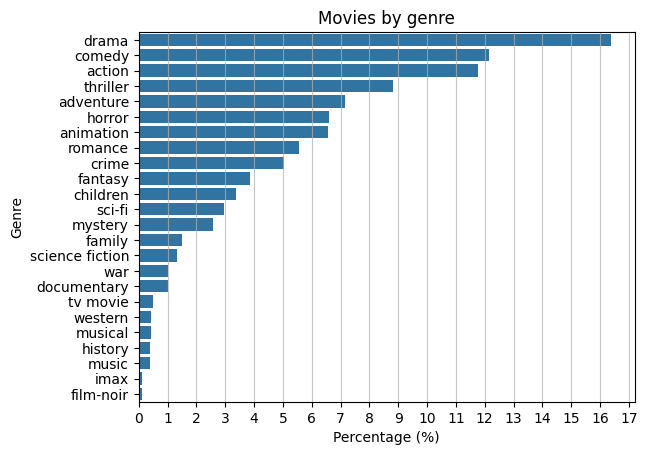

In [7]:
# LEAVE AS-IS

def plot_genres(df):
    
    # Convert genres into a list (i.e., "explode" it)
    exploded_genres = df['genres'].str.split(',').explode().str.strip()

    # Create frequency DataFrame
    genre_counts = exploded_genres.value_counts().reset_index()
    genre_counts.columns = ['genre', 'count']
    genre_counts['percent'] = (genre_counts['count'] / genre_counts['count'].sum()) * 100

    # Create barchart
    sns.barplot(data=genre_counts, x='percent', y='genre', legend=False)
    plt.title('Movies by genre')
    plt.xlabel('Percentage (%)')
    plt.ylabel('Genre')
    
    # Add vertical lines
    # The instructor used AI to set this grid (Gemini 3.6 Flash)
    max_percentage = int(np.ceil(genre_counts['percent'].max()))
    plt.xticks(np.arange(0, max_percentage + 1, 1 ))
    plt.grid(axis='x', alpha=0.7)
    
    plt.show()

plot_genres(movies1)

<font size="+1" color="#2680EB">**Merge genres** using the specification above.</font>

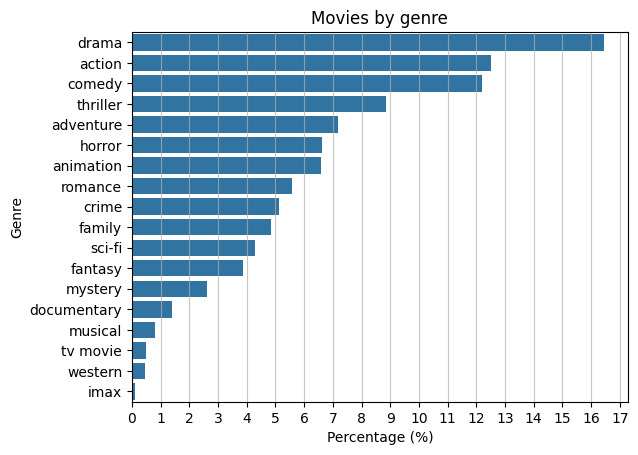

In [8]:
pairs_to_replace = [
    ('film-noir', 'crime'),
    ('music', 'musical'),
    ('science fiction', 'sci-fi'),
    ('history', 'documentary'),
    ('children', 'family'),
    ('war', 'action')
]

movies2 = movies1.copy()
# #AI (edited) to teach me about the \b regex
# YOUR CODE HERE
for old, new in pairs_to_replace:
    movies2["genres"] = movies2["genres"].str.replace(
        rf"\b{re.escape(old)}\b",
        new,
        regex=True
    )
    
movies2["genres"] = movies2["genres"].apply(
    lambda s: s if pd.isna(s) else ",".join(dict.fromkeys(s.split(",")))
)

plot_genres(movies2)

## 2.2. Merge genres and tags into keywords <font color="#2680EB">[15%]</font>

<font size="+1" color="#2680EB">**Create column "keywords".** It should contain a list, which should be the union of "genres" and "tags".</font>

In [9]:
# Merge source1 and source2 (comma-separated) into target (list)
def merge_csv_arrays(df, source1, source2, target):
    
    # Copy the dataframe
    dfc = df.copy()
    
    # YOUR CODE HERE
    # AI edited, I originally concatenate the strings with comma
    merged = []
    for a, b in zip(dfc[source1], dfc[source2]):
        items = []
        for value in (a, b):
            if isinstance(value, str):
                items += [x.strip() for x in value.split(",") if x.strip()]
        merged.append(list(dict.fromkeys(items)))  # union: no duplicates, order kept
    dfc[target] = merged
    
    # Replaces missing values with an empty list
    dfc[target] = dfc[target].mask(dfc[target].isna(), [[] for _ in range(len(dfc))])
    return dfc

movies3 = merge_csv_arrays(movies2, "genres", "tags", "keywords")

In [10]:
# LEAVE AS-IS

# Sample 3 random movies
for i in range(3):
    movie = movies3[['title', 'genres', 'tags', 'keywords']].sample().iloc[0]

    # Print genres, tags → keywords
    print(f"Title: {movie['title']}")
    print(f" genres={movie['genres']}, tags={movie['tags']} => keywords={movie['keywords']}")
    print()


Title: The Disappearance of Haruhi Suzumiya
 genres=adventure,animation,drama, tags=time travel,anime,supernatural,alternate timeline,japan,aliens,high school,wonderfully convoluted story,christmas,haruhi suzumiya => keywords=['adventure', 'animation', 'drama', 'time travel', 'anime', 'supernatural', 'alternate timeline', 'japan', 'aliens', 'high school', 'wonderfully convoluted story', 'christmas', 'haruhi suzumiya']

Title: A Whisker Away
 genres=animation,drama,romance, tags=nan => keywords=['animation', 'drama', 'romance']

Title: Teenage Mutant Ninja Turtles III
 genres=action,adventure,family, tags=franchise,comic book,time travel,superhero,ninja,martial arts,animation remade as live action,adapted from:comic,talking animals => keywords=['action', 'adventure', 'family', 'franchise', 'comic book', 'time travel', 'superhero', 'ninja', 'martial arts', 'animation remade as live action', 'adapted from:comic', 'talking animals']



# 3. Content-based recommendation

## 3.1. Compute TF-IDF vectors

In [11]:
# LEAVE AS-IS

tfidf = TfidfVectorizer(analyzer=lambda x: x, min_df=1)
tfidf_matrix = tfidf.fit_transform(movies3['keywords'])
print(f"The TF-IDF matrix has {tfidf_matrix.shape[0]} rows (movies)")
print(f"The TF-IDF matrix has {tfidf_matrix.shape[1]} columns (distinct keywords)")

The TF-IDF matrix has 9751 rows (movies)
The TF-IDF matrix has 7875 columns (distinct keywords)


## 3.2. Calculate most similar movies <font color="#2680EB">[20%]</font>

In [12]:
# LEAVE AS-IS

cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

print(f"The similarity matrix has {cosine_sim.shape[0]} rows and {cosine_sim.shape[1]} columns")
print(cosine_sim)

The similarity matrix has 9751 rows and 9751 columns
[[1.         0.         0.62458116 ... 0.63207312 0.         0.        ]
 [0.         1.         0.         ... 0.         0.         0.        ]
 [0.62458116 0.         1.         ... 0.20997285 0.35270144 0.        ]
 ...
 [0.63207312 0.         0.20997285 ... 1.         0.         0.        ]
 [0.         0.         0.35270144 ... 0.         1.         0.43488846]
 [0.         0.         0.         ... 0.         0.43488846 1.        ]]


<font size="+1" color="#2680EB">**Create functions "get_title", "get_index_by_movieid",  "get_movieid_by_index".** They should, respectively, return the title, the index of the row of a movie with id=movieid, and the movieid of the row of a movie indexed by index. In all cases, make sure they return a null ("None") if this is not found.</font>

In [13]:
def get_title_by_movieid(df, movie_id):
    # YOUR CODE HERE
    filtered_rows = df.loc[df["id"]==movie_id]
    return filtered_rows["title"].iloc[0] if len(filtered_rows) else None

def get_index_by_movieid(df, movie_id):
    # YOUR CODE HERE
    filtered_indices = df.index[df["id"]==movie_id]
    return int(filtered_indices[0]) if len(filtered_indices) else None

def get_movieid_by_index(df, idx):
    # YOUR CODE HERE
    return df["id"].iloc[idx] if 0 <= idx < len(df) else None

In [14]:
# LEAVE AS-IS

# Test with a random sample
for i in range(5):
    movie_id = movies3.sample()['id'].iloc[0]
    print(f"Movie id    : {movie_id}")
    print(f"Title       : {get_title_by_movieid(movies3, movie_id)}")
    idx = get_index_by_movieid(movies3,movie_id)
    print(f"Movie index : {idx}" )
    movie_id_recovered = get_movieid_by_index(movies3,idx)
    print(f"Check id    : {movie_id_recovered}")
    
    assert movie_id_recovered == movie_id
    print()

Movie id    : 205775
Title       : In the Heart of the Sea
Movie index : 4607
Check id    : 205775

Movie id    : 298382
Title       : The Dressmaker
Movie index : 7050
Check id    : 298382

Movie id    : 13805
Title       : Disaster Movie
Movie index : 5273
Check id    : 13805

Movie id    : 601722
Title       : Thicker Than Water
Movie index : 6466
Check id    : 601722

Movie id    : 619264
Title       : The Platform
Movie index : 2565
Check id    : 619264



<font size="+1" color="#2680EB">**Implement "get_similarities_for_movieid".** It should obtain the corresponding row in a similarity matrix, and return a dictionary where keys are movie ids and values are similarities.</font>

In [15]:
# Return all similarities to a given movie
def get_similarities_for_movieid(df, similarities, source_id):
    source_idx = get_index_by_movieid(df, source_id)
    sim_row = similarities[source_idx]
    output = {}
    
    # YOUR CODE HERE
    for idx, value in enumerate(sim_row):
        output[get_movieid_by_index(df, idx)] = value
    
    return output

In [16]:
# LEAVE AS-IS
    
# Test your function
test_movie_id = 4256
print(f"Test movie_id {test_movie_id}, title '{movies3[movies3['id']==test_movie_id]['title'].values[0]}'")

# Call your function
sim_dictionary = get_similarities_for_movieid(movies3, cosine_sim, 4256)

# Samples some key, value pairs from the result
sample_size = 10
sim_dictionary_sample = dict(random.sample(list(sim_dictionary.items()), sample_size))

# Prints those
for other_movie_id, sim in sim_dictionary_sample.items():
    other_movie_title = movies3[movies3['id']==other_movie_id]['title'].values[0]
    print(f"{other_movie_id} ({other_movie_title}): {sim:.4f}")

Test movie_id 4256, title 'Scary Movie 3'
816952 (My Best Friend's Exorcism): 0.1884
12795 (Another Gay Movie): 0.0203
776305 (Belle): 0.0000
1646 (Freedom Writers): 0.0000
10866 (Joy Ride): 0.0000
785545 (Shaun the Sheep: The Flight Before Christmas): 0.0550
113 (Spring, Summer, Fall, Winter... and Spring): 0.0000
492621 (The Midnight Man): 0.1477
139455 (Silent Night): 0.1477
14324 (Virgin Territory): 0.0397


## 3.3. Implement content-based recommendations <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Implement content based recommendations.**</font>

In [17]:
def content_based_recommendations(movies, similarities, movie_id, num_movies=10):
    
    recommendations = []
    sim_dictionary = get_similarities_for_movieid(movies, similarities, movie_id)
    
    # YOUR CODE HERE
    sim_list = list(sim_dictionary.items())
    sim_list = [pair for pair in sim_list if pair[0] != movie_id]
    sim_list = sorted(sim_list, key = lambda sim_pair: sim_pair[1], reverse=True)
    for top_idx in range(num_movies):
        recom_movie_id = sim_list[top_idx][0]
        recommendations.append(
            {
                "movie_id": movie_id,
                "recom_movie_id": recom_movie_id,
                "similarity": sim_list[top_idx][1],
                "title": get_title_by_movieid(movies, recom_movie_id),
                "keywords": movies[movies["id"]==recom_movie_id]["keywords"].iloc[0],
            }
        )
        
    
    return pd.DataFrame.from_records(recommendations,
                                     columns=['movie_id', 'recom_movie_id', 'similarity', 'title', 'keywords'])

In [18]:
# LEAVE AS-IS

# Do not truncate any columns (the "keywords" column is quite large)
pd.set_option('display.max_colwidth', None)

# Obtain and display recommendations for a movie
display(content_based_recommendations(movies3, cosine_sim, 129, 10))

,movie_id,recom_movie_id,similarity,title,keywords
0,129,128,0.594452,Princess Mononoke,"[action, adventure, animation, hayao miyazaki, studio ghibli, anime, atmospheric, surreal, fantasy world, environmental, fantasy, japan, dystopia]"
1,129,4935,0.545231,Howl's Moving Castle,"[adventure, animation, fantasy, studio ghibli, anime, hayao miyazaki, steampunk, dreamlike, fantasy world, stylized, magic, whimsical]"
2,129,10515,0.452817,Castle in the Sky,"[action, adventure, animation, studio ghibli, anime, hayao miyazaki, fantasy, imagination, visually appealing, steampunk, pirates, great soundtrack]"
3,129,242828,0.450916,When Marnie Was There,"[animation, drama, beautiful, studio ghibli, anime, hiromasa yonebayashi, friendship]"
4,129,8392,0.410851,My Neighbor Totoro,"[animation, family, drama, studio ghibli, hayao miyazaki, anime, visually appealing, feel good movie, cute, fantasy, feel-good, nature, great soundtrack]"
5,129,81,0.410281,Nausicaä of the Valley of the Wind,"[adventure, animation, drama, studio ghibli, hayao miyazaki, post-apocalyptic, strong female lead, anime, environmental, dystopic future, sci-fi, fantasy world]"
6,129,16859,0.392996,Kiki's Delivery Service,"[adventure, animation, family, studio ghibli, anime, hayao miyazaki, strong female lead, witch, feel-good, magic, coming of age, miyazaki]"
7,129,347201,0.365378,Boruto: Naruto the Movie,"[action, animation, fantasy, anime]"
8,129,83090,0.365378,Saint Seiya: Evil Goddess Eris,"[action, animation, fantasy, anime]"
9,129,8843,0.359096,The Cell,"[drama, horror, thriller, surreal, serial killer, virtual reality, atmospheric, alternate reality, stylized, psychological, dreamlike, beautiful cinematography, dreams]"


In [20]:
# Set MOVIE_IDS to a list of three movie ids.
MOVIE_IDS = [10515, 420817, 10674]

for movie_id in (MOVIE_IDS):
    print(f"movie title: {get_title_by_movieid(movies3, movie_id)}")
    display(content_based_recommendations(movies3, cosine_sim, movie_id, 10))


movie title: Castle in the Sky


,movie_id,recom_movie_id,similarity,title,keywords
0,10515,8392,0.539139,My Neighbor Totoro,"[animation, family, drama, studio ghibli, hayao miyazaki, anime, visually appealing, feel good movie, cute, fantasy, feel-good, nature, great soundtrack]"
1,10515,4935,0.532194,Howl's Moving Castle,"[adventure, animation, fantasy, studio ghibli, anime, hayao miyazaki, steampunk, dreamlike, fantasy world, stylized, magic, whimsical]"
2,10515,129,0.452817,Spirited Away,"[adventure, animation, fantasy, anime, studio ghibli, hayao miyazaki, dreamlike, atmospheric, alternate reality, beautiful, surreal]"
3,10515,128,0.433089,Princess Mononoke,"[action, adventure, animation, hayao miyazaki, studio ghibli, anime, atmospheric, surreal, fantasy world, environmental, fantasy, japan, dystopia]"
4,10515,227707,0.417438,The Adventurer: The Curse of the Midas Box,"[adventure, fantasy, steampunk]"
5,10515,81,0.382389,Nausicaä of the Valley of the Wind,"[adventure, animation, drama, studio ghibli, hayao miyazaki, post-apocalyptic, strong female lead, anime, environmental, dystopic future, sci-fi, fantasy world]"
6,10515,347201,0.375501,Boruto: Naruto the Movie,"[action, animation, fantasy, anime]"
7,10515,83090,0.375501,Saint Seiya: Evil Goddess Eris,"[action, animation, fantasy, anime]"
8,10515,16859,0.366279,Kiki's Delivery Service,"[adventure, animation, family, studio ghibli, anime, hayao miyazaki, strong female lead, witch, feel-good, magic, coming of age, miyazaki]"
9,10515,176983,0.363498,One Piece Film: Z,"[action, adventure, animation, anime]"


movie title: Aladdin


,movie_id,recom_movie_id,similarity,title,keywords
0,420817,420818,0.301508,The Lion King,"[adventure, animation, family, remake, photorealistic, musical, lion, disney, theater, pam's list, live action/animation]"
1,420817,818110,0.266800,The Magic Flute,"[musical, fantasy, adventure]"
2,420817,204436,0.264287,Jack and the Cuckoo-Clock Heart,"[adventure, animation, drama, musical, romance, fantasy]"
3,420817,15947,0.255396,The Three Caballeros,"[animation, family, musical, disney]"
4,420817,46929,0.255396,Fun and Fancy Free,"[animation, family, musical, disney]"
5,420817,11887,0.237243,High School Musical 3: Senior Year,"[musical, disney, high school]"
6,420817,13649,0.224786,High School Musical 2,"[comedy, drama, musical, high school, disney]"
7,420817,809107,0.223095,Z-O-M-B-I-E-S 3,"[musical, fantasy, comedy]"
8,420817,381696,0.223095,Shrek the Musical,"[musical, comedy, fantasy]"
9,420817,783740,0.221511,Till We Meet Again,"[fantasy, romance, adventure]"


movie title: Mulan


,movie_id,recom_movie_id,similarity,title,keywords
0,10674,15947,0.411443,The Three Caballeros,"[animation, family, musical, disney]"
1,10674,46929,0.411443,Fun and Fancy Free,"[animation, family, musical, disney]"
2,10674,9948,0.367468,The Fox and the Hound 2,"[adventure, animation, family, disney]"
3,10674,10010,0.367468,Brother Bear 2,"[adventure, animation, family, disney]"
4,10674,10882,0.336498,Sleeping Beauty,"[animation, family, musical, disney, visually appealing, fairy tales, fairy tale, classic, magic, fantasy, dragons, heroine]"
5,10674,14906,0.323136,Saludos Amigos,"[animation, family, comedy, disney]"
6,10674,452557,0.318741,Wolf Warrior 2,"[action, china]"
7,10674,850818,0.313110,"Barbie: Big City, Big Dreams","[animation, musical, family]"
8,10674,653247,0.313110,"Turu, the Wacky Hen","[family, animation, musical]"
9,10674,59981,0.313110,Legends of Oz: Dorothy's Return,"[animation, family, musical]"


## 3.4. Questions about recommendations <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Regarding movie 1**

What is the title of the movie you tested?

* Castle in the Sky

Which movies you would say are NOT relevant in the list of recommended movie, if any?
* I would say "One Piece Film: Z" is not revelant, while they are japanese anime movie too, but the styles are very different.

What is the *accuracy* of the recommendations, i.e., what is the percentage of movies in the list that you would consider relevant?

* I would say 60%, note that I only know part of the movies in the list.

**Regarding movie 2**
What is the title of the movie you tested?

* Aladdin

Which movies you would say are NOT relevant in the list of recommended movie, if any?
* I would say "High School Musical 3: Senior Year" and "High School Musical 2" are very different from Aladdin in my perspective.

What is the *accuracy* of the recommendations, i.e., what is the percentage of movies in the list that you would consider relevant?

* I would still say 50%, note that I only know part of the movies in the list.


**Regarding movie 3**
What is the title of the movie you tested?

* Mulan

Which movies you would say are NOT relevant in the list of recommended movie, if any?
* No, I briefly checked all of them in the list, and they gave me a same feeling. While Mulan story's background is China, and the recommended movies aren't, they mostly gave me a feeling of telling legend.

What is the *accuracy* of the recommendations, i.e., what is the percentage of movies in the list that you would consider relevant?

* I would say 90%, note that I am not familiar with many of the movies in the list.

<hr/>

**Regarding all the tested movies:**

Is there any of the movies for which you would say that an **infrequent keyword** (i.e., one having high inverse document frequency) substantially drives the results? Which movie and which keyword?

* "studio ghibli" drives the result for the recommended movies of Castle in the Sky. Giving the listing of 6 movies in the top 10 recommendation also contains "studio ghibli". And I think this is a good result, as the movies that also contain "studio ghibli" really do are similar.

Considering the information available on this dataset, and assuming you do not have access to other information, how would you improve this content-based recommender system? One bullet point per idea, stating the idea and **why** do you think that would improve the recommendations.

* If the knowledge from LLM doesn't not count for "do not have access to other information", we can use the domain knowledge LLM has to do preprocessing, like weighting keywords, extracting keywords from movie overview.
* We can first download the poster image with the url, then use OCR to extract strings from the poster.
* Director is also a very good indicator, audience tend to like the movies from the same director.
* Year is also a good indicator, audience likely will enjoy movie from similar era.
* Popularity can take into account too, some audience like movies that is popular, some audience like movie that isn't the mainstream.
* Rating can also be taken into account, the recommendation of course should recommend movies with higher rating compared to lower ones, however, I'm not sure whether this counts as "content-based recommender".


<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that I have not copied it from others, or from external sources without citing them, and that I have followed the AI instructions stated above.</font>